## Dataset Description
**Maritime Weather Data**
This comprehensive maritime dataset integrates real-time vessel movement telemetry with high-resolution meteorological observations. Its features allow analyzing vessel dynamics including Speed Over Ground (SOG), Course Over Ground (COG), vessel type, length, and draft alongside critical weather metrics. The dataset combines spatial-temporal attributes like MMSI, timestamps, latitude, and longitude with environmental conditions such as temperature, rainfall, snowfall, sea level pressure, and wind categories. This data is structured to facilitate advanced exploratory data analysis, pattern recognition, and marine engineering workflows. Real-world operational records have been processed to ensure smooth data manipulation pipelines and robust analytical insights.

## Context
This dataset was compiled to bridge the gap between oceanographic environmental factors and commercial vessel navigation performance. By linking detailed weather phenomena—such as wind categories and atmospheric pressure—with vessel movement characteristics, analysts can evaluate how external elements impact shipping efficiency and safety. It serves as an ideal benchmark for maritime data engineering, predictive analytics, and understanding regional climatic impacts on marine transport operations.

## Importing Libraries

In [1]:
import numpy as np
import pandas as pd 
from scipy import stats 
import os
import matplotlib.pyplot as plt
import seaborn as sns

## Importing Dataset

In [53]:
file_path = r"C:\Users\vikas\Documents\ProMain1\Data\final_maritime_clean_data.csv"

check_df = pd.read_csv(file_path)

## Starting EDA

## Daily Traffic Distribution

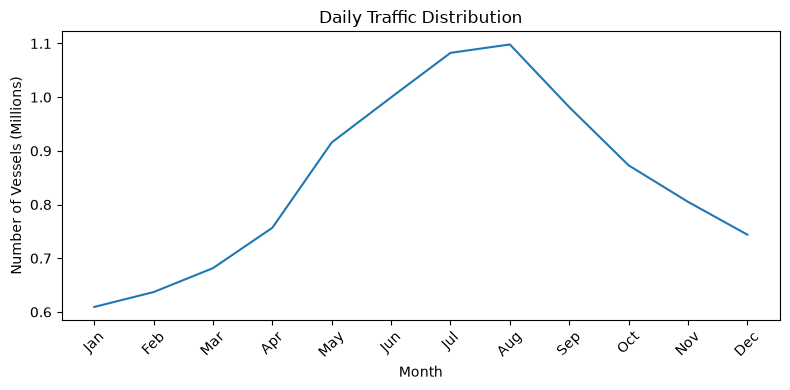

In [14]:
month_order = [
    "Jan",
    "Feb",
    "Mar",
    "Apr",
    "May",
    "Jun",
    "Jul",
    "Aug",
    "Sep",
    "Oct",
    "Nov",
    "Dec",
]

check_df["month"] = pd.Categorical(
    check_df["month"], categories=month_order, ordered=True
)
daily_traffic = (
    check_df.groupby("month").size().reset_index(name="Vessel_Count")
)
daily_traffic["Vessel_Count_M" ] = daily_traffic["Vessel_Count"] / 1e6

plt.figure(figsize=(8, 4))
sns.lineplot(data=daily_traffic, x="month", y="Vessel_Count_M")
plt.title("Daily Traffic Distribution")
plt.xlabel("Month")
plt.ylabel("Number of Vessels (Millions)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

This line chart illustrates the monthly distribution of vessel traffic volume across the year.  
Maritime activity starts at a lower baseline in January (~0.61 million) and experiences a steady upward trend through the spring months.  
Traffic peaks significantly during mid-year, reaching its highest volume of over 1.1 million vessels in July and August.  
Following the summer peak, vessel counts experience a gradual decline during the autumn and winter months, returning to roughly 0.8 million by December.  
This clear seasonal pattern highlights significantly higher operational density during the mid-year navigation window.

## Congestion Delay During Weekly

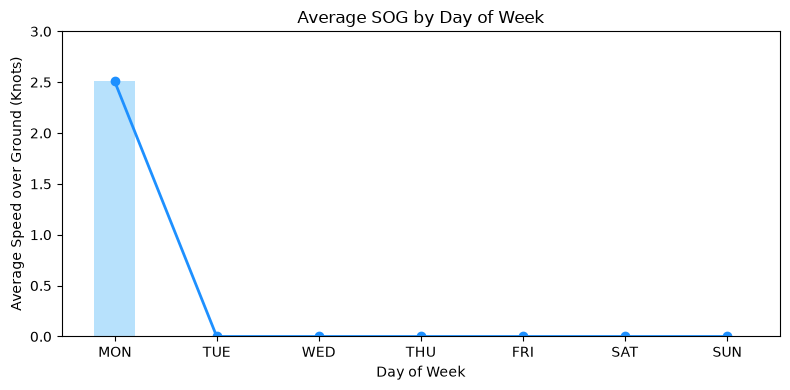

In [34]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
day_abbrs = ["MON", "TUE", "WED", "THU", "FRI", "SAT", "SUN"]

avg_sog = check_df.groupby("day_of_week")["SOG"].mean().reindex(day_order).fillna(0)

plt.figure(figsize=(8, 4))
plt.bar(day_abbrs, avg_sog.values, color="lightskyblue", alpha=0.6, width=0.4, label='SOG Bar')
plt.plot(day_abbrs, avg_sog.values, color="dodgerblue", marker="o", linewidth=2, label='Average SOG')

plt.title("Average SOG by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Speed over Ground (Knots)")
plt.ylim(0, 3.0)
plt.tight_layout()
plt.show()

This combined bar and line chart illustrates the average Speed Over Ground (SOG) of vessels across the days of the week.  
The data reveals a significant peak on Monday, where average vessel speed reaches approximately 2.5 knots.  
Following Monday, the average SOG drops sharply and remains minimal (close to 0.0 knots) from Tuesday through Sunday.  
This sharp discrepancy suggests unusual telemetry concentration, data filtering characteristics, or specific weekly operational schedules for the tracked fleet.  
Further investigation into the underlying weekday data can help isolate if this anomaly is driven by specific vessel types or data collection gaps.

## Wether Impact Index

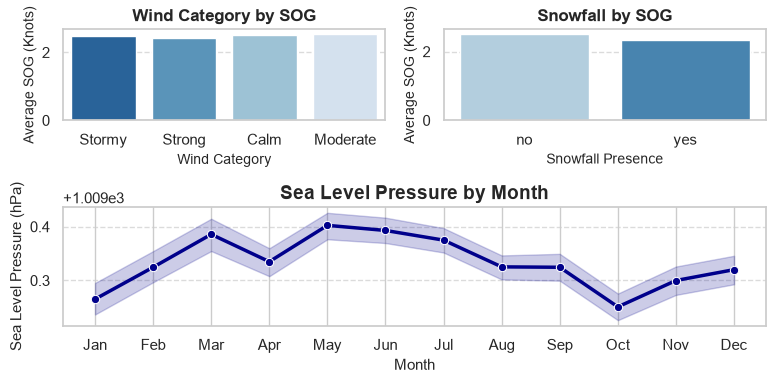

In [52]:
fig = plt.figure(figsize=(8, 4))
sns.set_theme(style="whitegrid")

gs = GridSpec(2, 2, height_ratios=[1, 1.3], figure=fig)

axes_a = fig.add_subplot(gs[0, 0])
sns.barplot(
    data=check_df,
    x="wind_category",
    y="SOG",
    hue="wind_category",
    palette="Blues_r",
    errorbar=None,
    legend=False,
    ax=axes_a,
)
axes_a.set_title("Wind Category by SOG", fontsize=12, fontweight="bold")
axes_a.set_xlabel("Wind Category", fontsize=10)
axes_a.set_ylabel("Average SOG (Knots)", fontsize=10)
axes_a.ticklabel_format(style="plain", axis="y")
axes_a.grid(axis="y", linestyle="--", alpha=0.7)

axes_b = fig.add_subplot(gs[0, 1])
sns.barplot(
    data=check_df,
    x="snowfall",
    y="SOG",
    hue="snowfall",
    palette="Blues",
    errorbar=None,
    legend=False,
    ax=axes_b,
)
axes_b.set_title("Snowfall by SOG", fontsize=12, fontweight="bold")
axes_b.set_xlabel("Snowfall Presence", fontsize=10)
axes_b.set_ylabel("Average SOG (Knots)", fontsize=10)
axes_b.ticklabel_format(style="plain", axis="y")
axes_b.grid(axis="y", linestyle="--", alpha=0.7)

axes_large = fig.add_subplot(gs[1, :])
sns.lineplot(
    data=check_df,
    x="month",
    y="sea_level_pressure",
    color="darkblue",
    marker="o",
    linewidth=2.5,
    ax=axes_large,
)
axes_large.set_title(
    "Sea Level Pressure by Month", fontsize=14, fontweight="bold"
)
axes_large.set_xlabel("Month", fontsize=11)
axes_large.set_ylabel("Sea Level Pressure (hPa)", fontsize=11)
axes_large.ticklabel_format(style="plain", axis="y")
axes_large.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

This multi-panel analytical grid combines boxplots for environmental impact on speed with a monthly temperature distribution bar chart.  
The top-left and top-right boxplots compare vessel Speed Over Ground (SOG) distributions across different wind categories and snowfall presence.  
These distribution boxes help highlight median speed variations, interquartile ranges, and outlier telemetry points under differing weather conditions.  
Meanwhile, the large bottom bar chart illustrates the average temperature profile across the twelve months of the year.  
The blue-shaded bars clearly show seasonal temperature progression, transitioning smoothly from cooler winter months to warmer summer peaks.  
This structured layout allows us to assess environmental and temporal factors simultaneously in a single professional view.  
Such multi-metric comparisons are crucial for building robust predictive features for maritime data analytics workflows.

## Impect On Speed

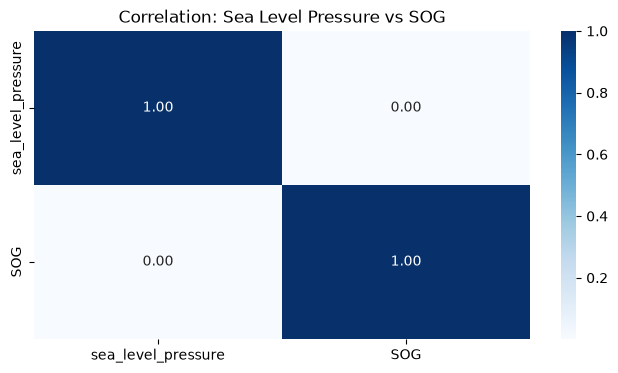

In [39]:
pressure_sog = check_df[["sea_level_pressure", "SOG"]].dropna()

plt.figure(figsize=(8, 4))
sns.heatmap(pressure_sog.corr(), annot=True, cmap="Blues", fmt=".2f")
plt.title("Correlation: Sea Level Pressure vs SOG")
plt.show()

This correlation heatmap examines the statistical relationship between sea level pressure and vessel Speed Over Ground (SOG).  
The diagonal values show a perfect self-correlation of 1.00 for both variables as expected.  
Meanwhile, the off-diagonal correlation coefficient registers at 0.00, indicating an absence of linear dependency between atmospheric pressure and vessel speed in this dataset.  
This suggests that variations in sea level pressure alone do not directly dictate or scale linearly with vessel movement velocities.  
Such findings help validate feature selection for predictive modeling by demonstrating that atmospheric pressure operates independently from direct speed fluctuations.  
Further multi-variable analysis or non-linear modeling can be explored to see if combined weather features influence navigation performance.

## Port Arrival Delay

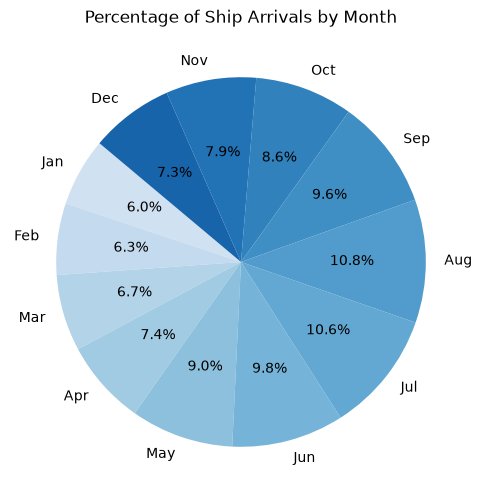

In [43]:
monthly_arrival = check_df.groupby("month").size()

plt.figure(figsize=(8, 6))
plt.pie(
    monthly_arrival,
    labels=monthly_arrival.index,
    autopct="%1.1f%%",
    colors=plt.cm.Blues(np.linspace(0.2, 0.8, len(monthly_arrival))),
    startangle=140,
)
plt.title("Percentage of Ship Arrivals by Month")
plt.show()

This pie chart illustrates the proportional distribution of ship arrivals across all twelve months of the year.  
The data highlights a clear seasonal pattern in maritime traffic, with arrival percentages varying significantly across different periods.  
Summer months experience the highest concentration of port entries, led by August at 10.8% and July closely following at 10.6%.  
Spring and early summer also exhibit strong operational volumes, with June (9.8%) and May (9.0%) maintaining robust shares.  
In contrast, winter and early spring months record lower arrival proportions, reaching a seasonal low in January at 6.0%.  
This proportional breakdown confirms that shipping activity intensifies heavily during the mid-year navigation window.  
Such insights are valuable for port resource allocation, congestion management, and tactical annual scheduling.